In [ ]:
RUN_VAL = True        # also score the frozen val split (official PQ + Dice), ~25-35 min on a T4
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA L4, 23034 MiB


In [ ]:
import os
BRANCH = "Dev"
REPO = "github.com/amiruliman592/Kaggle-Competition-.git"
try:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
except Exception:
    token = None
url = f"https://{token}@{REPO}" if token else f"https://{REPO}"
if os.path.exists("/content/solar"):
    !git -C /content/solar pull -q origin {BRANCH}
else:
    !git clone -q --depth 1 -b {BRANCH} {url} /content/solar
%cd /content/solar
os.environ["SOLAR_ROOT"] = "/content/solar"
!git log --oneline -1

/content/solar
7ad3c3d (grafted, HEAD -> Dev, origin/Dev) Kimee: final weights in repo (exp101 m28 + r50, split parts + SHA-256 manifest)


In [ ]:
!pip install -q -r requirements.txt
# same Detectron2 commit as requirements-lock.txt
!pip install -q --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git@1e3e13bbf607b54f62205c4c33922521822fb298'
import torch, detectron2
print("torch", torch.__version__, "| detectron2", detectron2.__version__,
      "| GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
torch 2.14.1+cu130 | detectron2 0.6 | GPU NVIDIA L4


In [ ]:
!python src/weights_io.py unpack --dir weights
!python -m pytest -q -p no:warnings tests/test_final_pipeline.py tests/test_flip.py tests/test_rle_and_submission.py tests/test_official_metric.py

[Weights] x101_2048_m28: OK (429.8 MB, SHA-256 checked) -> weights/x101_2048_m28.pth
[Weights] r50_2048: OK (176.2 MB, SHA-256 checked) -> weights/r50_2048.pth
.........................                                                [100%]
25 passed in 84.59s (0:01:24)


In [ ]:
!python src/final_pipeline.py predict --split test --out submissions/submission_final.csv --raw-out output/raw_preds_final_test.json.gz --report output/report_test.json

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[Inference] Loading model from: /content/solar/weights/x101_2048_m28.pth
[Inference] Loading model from: /content/solar/weights/r50_2048.pth
Final pipeline:   0% 0/180 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upco

In [ ]:
!python src/submit_from_raw.py "Result Phase 6/Mirul/raw_preds_tta2_m28_r50_test.json.gz" submissions/submission_exp101_from_raw.csv --score-thr 0.6
!python src/final_pipeline.py compare --a submissions/submission_final.csv --b submissions/submission_exp101_from_raw.csv

[SubmitFromRaw] thr=0.6 close=5 min_area=50 drop_frac=0.2
[Submission] Saved 1256 rows (180 images) to submissions/submission_exp101_from_raw.csv
[Validate] submissions/submission_exp101_from_raw.csv: 1256 rows, 177 images
[Validate] PASS
{
 "masks_a": 1255,
 "masks_b": 1256,
 "a_matched_in_b": 1.0,
 "median_iou": 1.0,
 "identical": false
}


In [ ]:
if RUN_VAL:
    !python src/final_pipeline.py predict --split val --report output/report_val.json

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[Inference] Loading model from: /content/solar/weights/x101_2048_m28.pth
[Inference] Loading model from: /content/solar/weights/r50_2048.pth
Final pipeline:   0% 0/141 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upco

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[Inference] Loading model from: weights/x101_2048_m28.pth
[Inference] Loading model from: weights/r50_2048.pth


Final pipeline:   0%|          | 0/2 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1110 10:22:50.382000 846 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.
Final pipeline: 100%|██████████| 2/2 [00:11<00:00,  5.85s/it]


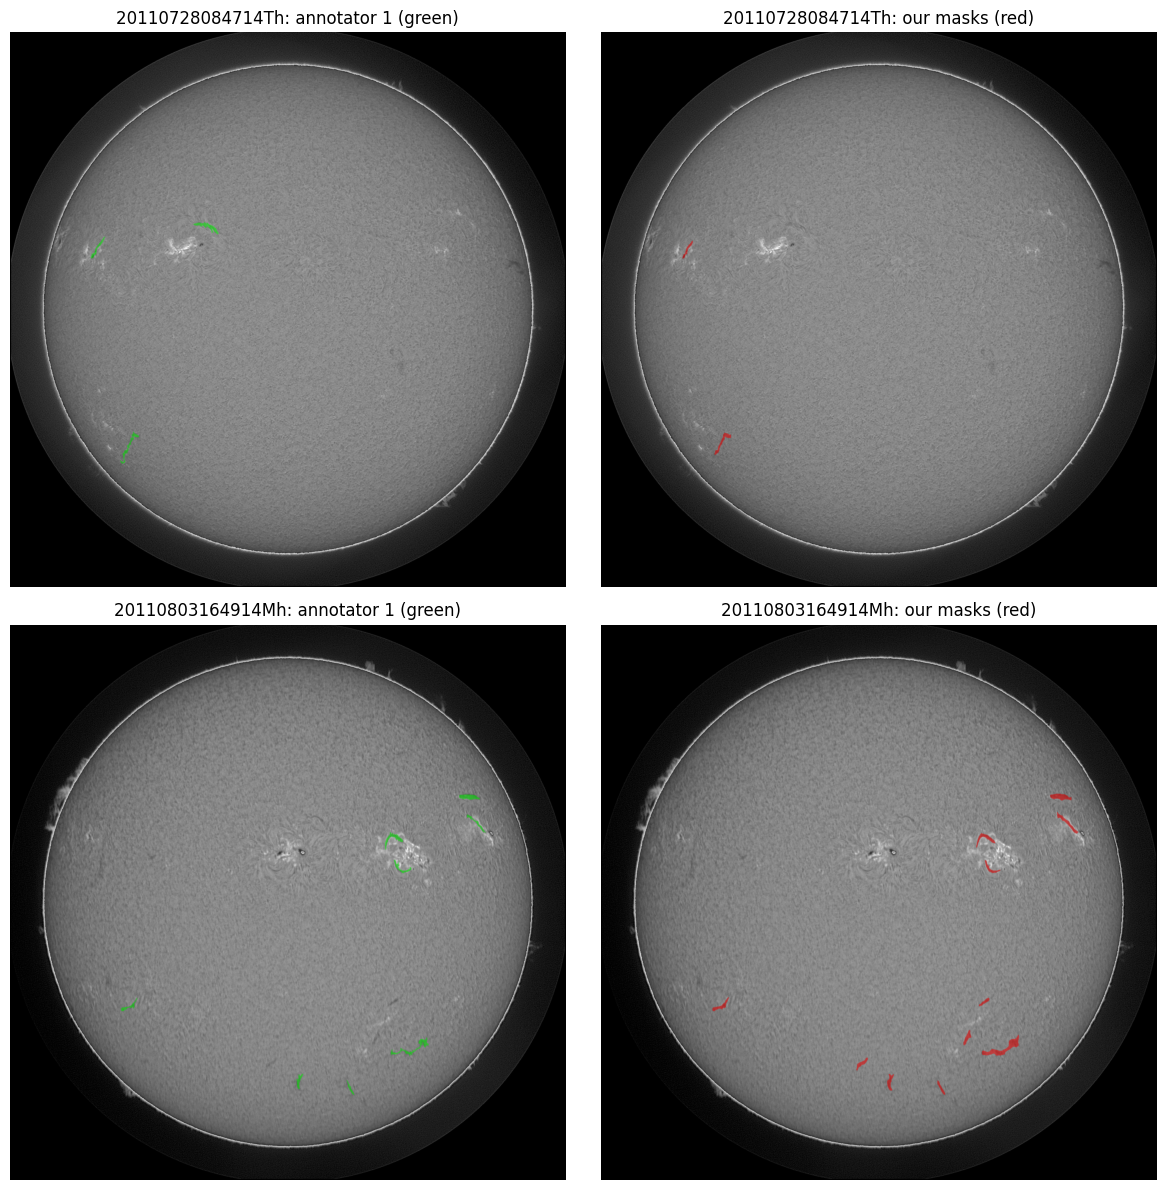

In [ ]:
import sys, cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, "src")
from final_pipeline import load_predictors, predict
from annotations import load_gt_rles
from preprocess import image_path
from split import load_split
from pycocotools import mask as coco_mask

stems = load_split()[1][:2]
preds = predict([image_path(s, "train") for s in stems], load_predictors(Path("weights")))[1]
gt = load_gt_rles(stems)

def overlay(img, rles, color):
    out = img.copy()
    for r in rles:
        m = coco_mask.decode(r).astype(bool)
        out[m] = (0.5 * out[m] + 0.5 * np.array(color)).astype(np.uint8)
    return out

fig, ax = plt.subplots(len(stems), 2, figsize=(12, 6 * len(stems)))
for i, s in enumerate(stems):
    img = cv2.cvtColor(cv2.imread(str(image_path(s, "train"))), cv2.COLOR_BGR2RGB)
    ax[i, 0].imshow(overlay(img, gt.get(s, []), (0, 255, 0))); ax[i, 0].set_title(f"{s}: annotator 1 (green)")
    ax[i, 1].imshow(overlay(img, preds.get(s, []), (255, 0, 0))); ax[i, 1].set_title(f"{s}: our masks (red)")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()

In [10]:
if RUN_VAL:
    !python src/final_pipeline.py predict --split val --report output/report_val.json

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[Inference] Loading model from: /content/solar/weights/x101_2048_m28.pth
[Inference] Loading model from: /content/solar/weights/r50_2048.pth
Final pipeline:   0% 0/141 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upco

In [11]:
!cd /content/solar && zip -j /content/final_run.zip output/report_test.json output/report_val.json output/raw_preds_final_test.json.gz submissions/submission_final.csv
from google.colab import files; files.download("/content/final_run.zip")


  adding: report_test.json (deflated 31%)
  adding: report_val.json (deflated 38%)
  adding: raw_preds_final_test.json.gz (deflated 0%)
  adding: submission_final.csv (deflated 63%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>